<a href="https://colab.research.google.com/github/lilad25/FUNDAI-Lab8/blob/main/Lab8_Supervised_Learning_Badon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 8: Supervised Learning Algorithms
## Fundamentals of Artificial Intelligence

**Name:** Adrian N. Badon  
**Course:** BSIT  
**Section:** BSIT-3F  
**Date:** November 5, 2026  
**GitHub URL:** *https://github.com/lilad25/FUNDAI-Lab8*

**Datasets used by the handout's sample code:**
1. California Housing — `sklearn.datasets.fetch_california_housing`
2. Breast Cancer — `sklearn.datasets.load_breast_cancer`

**Note:** The handout's information table mentions GitHub raw dataset URLs, but its step-by-step example uses these scikit-learn dataset loaders. This notebook follows the example code. Check with your instructor if raw GitHub dataset URLs are required.

## Step 3 — Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_squared_error, r2_score, accuracy_score,
    confusion_matrix, classification_report, roc_curve, auc,
    ConfusionMatrixDisplay
)
from sklearn.datasets import fetch_california_housing, load_breast_cancer

import warnings
warnings.filterwarnings('ignore')

# Part A — Linear Regression
Predict median house value from California housing features.

## Step 4 — Load Housing Data

In [2]:
housing = fetch_california_housing()
X_housing = pd.DataFrame(housing.data, columns=housing.feature_names)
y_housing = housing.target

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_housing, y_housing, test_size=0.2, random_state=42
)

print(f"Training set size: {X_train_reg.shape}")
print(f"Testing set size: {X_test_reg.shape}")
X_housing.head()

Training set size: (16512, 8)
Testing set size: (4128, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


## Step 5 — Train Linear Regression Model

In [3]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_reg, y_train_reg)

y_pred_reg = lin_reg.predict(X_test_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)

print("LINEAR REGRESSION RESULTS")
print("=" * 30)
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

LINEAR REGRESSION RESULTS
RMSE: 0.7456
R2 Score: 0.5758


## Step 6 — Interpret the Coefficients
### Interpreting the Weights

The table is sorted by absolute coefficient size. A positive coefficient means the prediction increases as that feature increases, **holding other features constant**. A negative coefficient means it decreases. Because features have different units, the largest raw coefficient is not necessarily the most important feature overall.

In [4]:
coefficients = pd.DataFrame({
    'Feature': X_housing.columns,
    'Coefficient (Weight)': lin_reg.coef_
}).sort_values(by='Coefficient (Weight)', key=abs, ascending=False)

print(coefficients.to_string(index=False))
strongest = coefficients.iloc[0]
print(f"\nLargest absolute coefficient: {strongest['Feature']}")
print(f"Direction: {'Positive' if strongest['Coefficient (Weight)'] > 0 else 'Negative'}")
print(f"Linear regression intercept: {lin_reg.intercept_:.4f}")

   Feature  Coefficient (Weight)
 AveBedrms              0.783145
    MedInc              0.448675
 Longitude             -0.433708
  Latitude             -0.419792
  AveRooms             -0.123323
  HouseAge              0.009724
  AveOccup             -0.003526
Population             -0.000002

Largest absolute coefficient: AveBedrms
Direction: Positive
Linear regression intercept: -37.0233


# Part B — Logistic Regression
Classify tumors as **malignant (0)** or **benign (1)**.

## Step 7 — Load Breast Cancer Data

In [5]:
cancer = load_breast_cancer()
X_cancer = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_cancer = cancer.target

X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X_cancer, y_cancer, test_size=0.3,
    stratify=y_cancer, random_state=42
)
print(f"Training set: {X_train_log.shape}")
print(f"Testing set: {X_test_log.shape}")

Training set: (398, 30)
Testing set: (171, 30)


## Step 8 — Train Logistic Regression in a Pipeline

In [6]:
log_reg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=10000, random_state=42))
])

log_reg_pipeline.fit(X_train_log, y_train_log)
y_pred_log = log_reg_pipeline.predict(X_test_log)

print("LOGISTIC REGRESSION RESULTS")
print("=" * 30)
print(f"Accuracy: {accuracy_score(y_test_log, y_pred_log):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_log, y_pred_log, target_names=cancer.target_names))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.9883

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171



## Step 9 — Confusion Matrix and ROC Curve
Both charts can be used as screenshots in your PDF report.

Confusion Matrix:
[[ 63   1]
 [  1 106]]


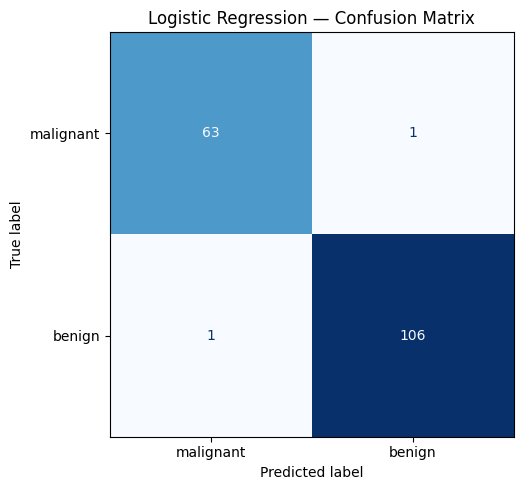

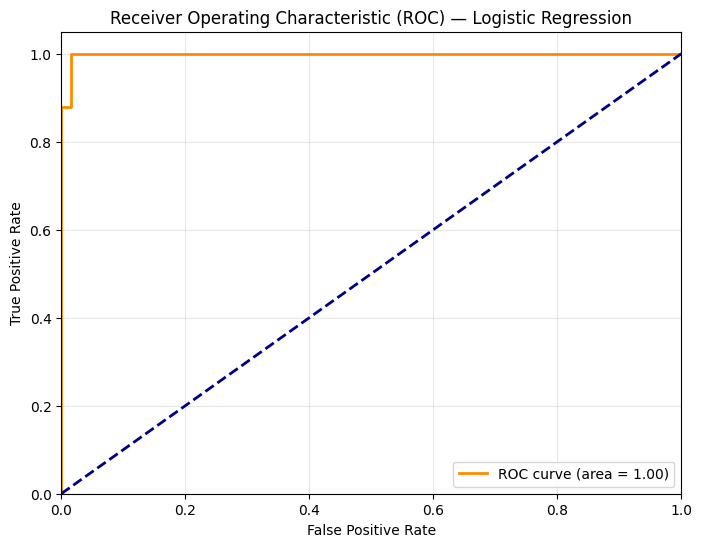

ROC AUC: 0.9981


In [7]:
cm = confusion_matrix(y_test_log, y_pred_log)
print("Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cancer.target_names).plot(
    ax=ax, cmap='Blues', colorbar=False
)
ax.set_title('Logistic Regression — Confusion Matrix')
plt.tight_layout()
plt.savefig('lab8_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

# ROC curve uses probability of class 1 (benign)
y_probs = log_reg_pipeline.predict_proba(X_test_log)[:, 1]
fpr, tpr, _ = roc_curve(y_test_log, y_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) — Logistic Regression')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.savefig('lab8_roc_curve.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"ROC AUC: {roc_auc:.4f}")

# Part C — Decision Trees
Compare an unpruned tree with a pruned tree using `max_depth=3`.

## Step 10 — Train an Unpruned Decision Tree

In [8]:
tree_unpruned = DecisionTreeClassifier(random_state=42)
tree_unpruned.fit(X_train_log, y_train_log)

train_acc_unpruned = accuracy_score(y_train_log, tree_unpruned.predict(X_train_log))
test_acc_unpruned = accuracy_score(y_test_log, tree_unpruned.predict(X_test_log))

print("UNPRUNED DECISION TREE")
print("=" * 30)
print(f"Training Accuracy: {train_acc_unpruned:.4f}")
print(f"Testing Accuracy:  {test_acc_unpruned:.4f}")
print(f"Tree Depth: {tree_unpruned.get_depth()}")
print(f"Number of Leaves: {tree_unpruned.get_n_leaves()}")

UNPRUNED DECISION TREE
Training Accuracy: 1.0000
Testing Accuracy:  0.9181
Tree Depth: 6
Number of Leaves: 16


### Unpruned Tree Visualization
Added because the PDF deliverables request unpruned **and** pruned tree images.

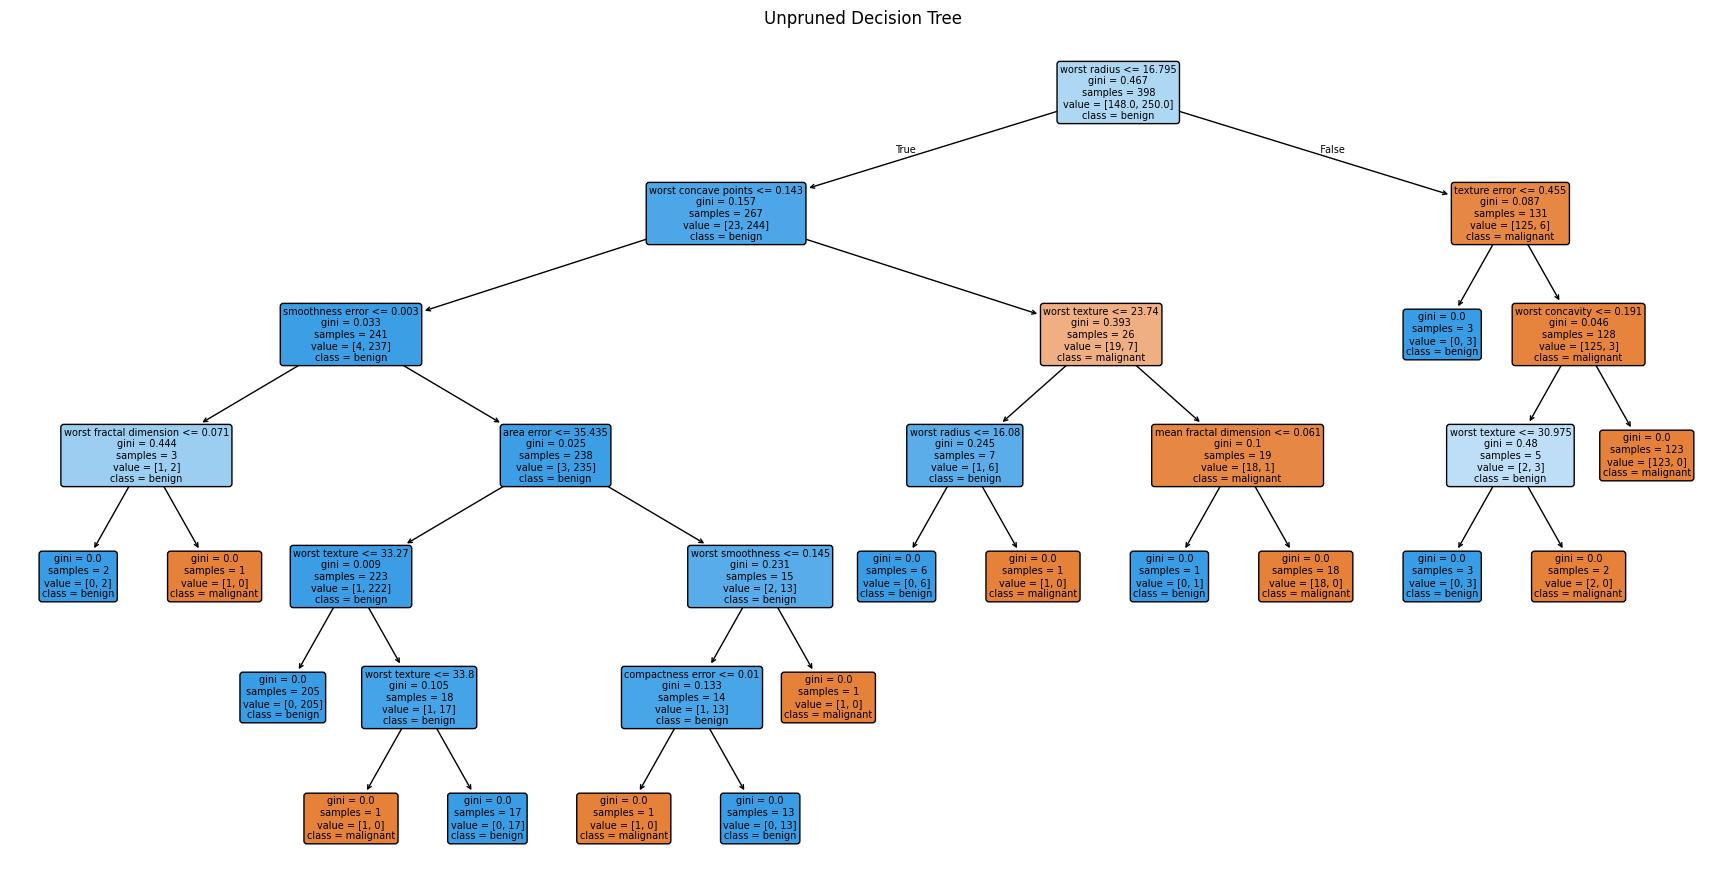

In [9]:
plt.figure(figsize=(22, 11))
plot_tree(
    tree_unpruned,
    feature_names=cancer.feature_names,
    class_names=list(cancer.target_names),
    filled=True, rounded=True, fontsize=7
)
plt.title('Unpruned Decision Tree')
plt.savefig('lab8_unpruned_tree.png', dpi=200, bbox_inches='tight')
plt.show()

## Step 11 — Train a Pruned Decision Tree

In [10]:
tree_pruned = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_pruned.fit(X_train_log, y_train_log)

train_acc_pruned = accuracy_score(y_train_log, tree_pruned.predict(X_train_log))
test_acc_pruned = accuracy_score(y_test_log, tree_pruned.predict(X_test_log))

print("PRUNED DECISION TREE (max_depth=3)")
print("=" * 30)
print(f"Training Accuracy: {train_acc_pruned:.4f}")
print(f"Testing Accuracy:  {test_acc_pruned:.4f}")
print(f"Tree Depth: {tree_pruned.get_depth()}")
print(f"Number of Leaves: {tree_pruned.get_n_leaves()}")

print("\nCOMPARISON")
print(f"Unpruned: train={train_acc_unpruned:.4f}, test={test_acc_unpruned:.4f}")
print(f"Pruned:   train={train_acc_pruned:.4f}, test={test_acc_pruned:.4f}")

PRUNED DECISION TREE (max_depth=3)
Training Accuracy: 0.9799
Testing Accuracy:  0.9240
Tree Depth: 3
Number of Leaves: 7

COMPARISON
Unpruned: train=1.0000, test=0.9181
Pruned:   train=0.9799, test=0.9240


## Step 12 — Visualize the Pruned Tree

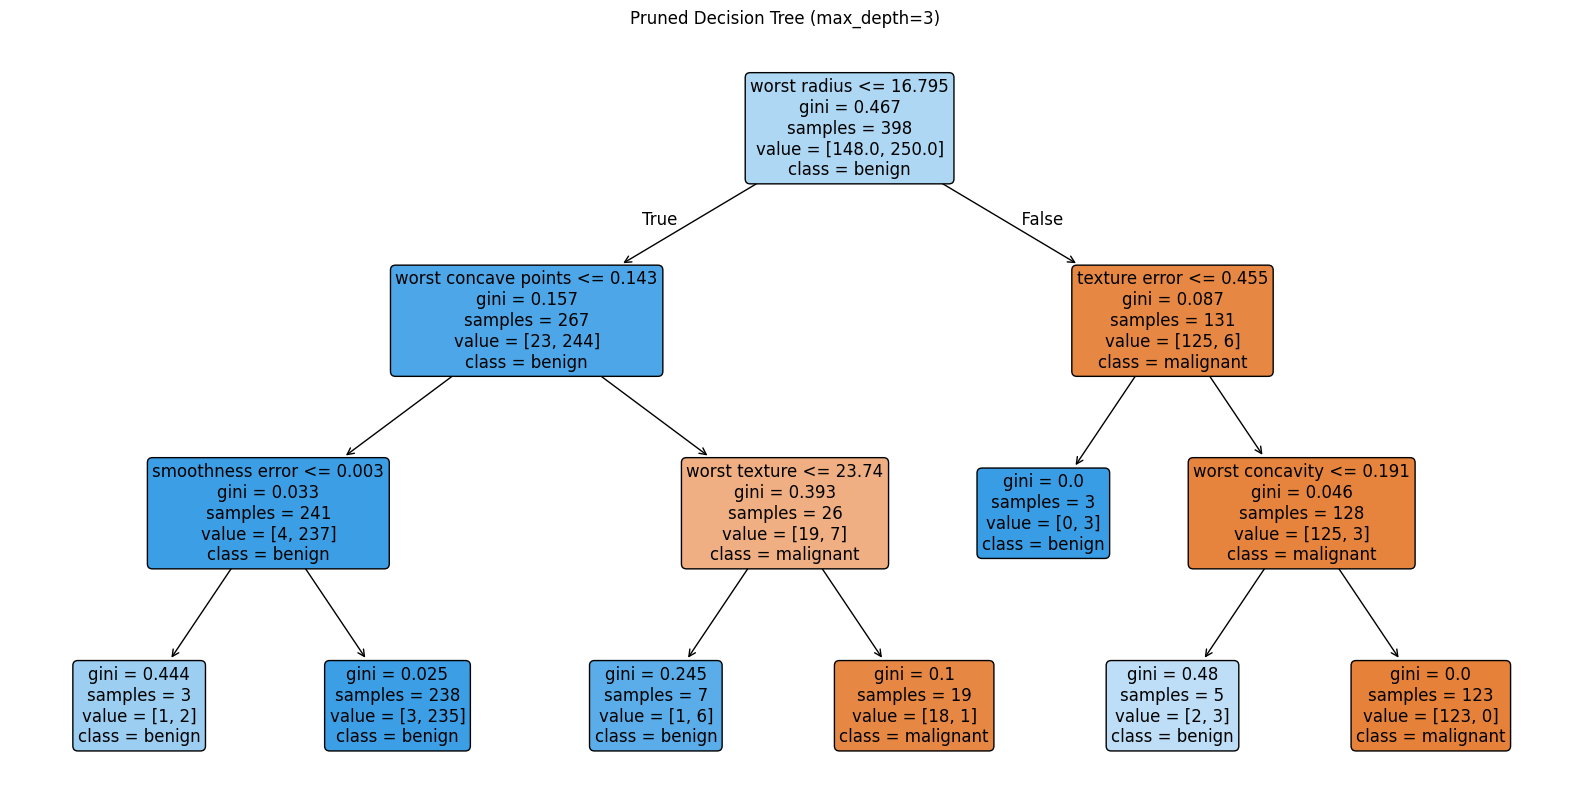

In [11]:
plt.figure(figsize=(20, 10))
plot_tree(
    tree_pruned,
    feature_names=cancer.feature_names,
    class_names=list(cancer.target_names),
    filled=True, rounded=True, fontsize=12
)
plt.title('Pruned Decision Tree (max_depth=3)')
plt.savefig('lab8_pruned_tree.png', dpi=200, bbox_inches='tight')
plt.show()

# Part D — k-Nearest Neighbors (k-NN)
Compare distance-based classification **with** and **without** scaling.

## Step 13 — The Danger of Forgetting to Scale
Euclidean distance is

$$d(x,y)=\sqrt{\sum_{j=1}^{p}(x_j-y_j)^2}.$$

If one feature is measured in thousands and another in small decimals, the large-number feature can dominate the distance even when it is not more informative. StandardScaler transforms each feature to roughly zero mean and unit standard deviation (based only on training data in each fold).

In [12]:
# Without scaling
knn_unscaled = KNeighborsClassifier(n_neighbors=5)
knn_unscaled.fit(X_train_log, y_train_log)
acc_unscaled = accuracy_score(y_test_log, knn_unscaled.predict(X_test_log))
print("k-NN WITHOUT SCALING")
print(f"Test Accuracy: {acc_unscaled:.4f}")

# With scaling: Pipeline prevents data leakage during CV
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=5))
])
cv_scores_scaled = cross_val_score(
    knn_pipeline, X_train_log, y_train_log, cv=5, scoring='accuracy'
)
knn_pipeline.fit(X_train_log, y_train_log)
acc_scaled = accuracy_score(y_test_log, knn_pipeline.predict(X_test_log))

print("\nk-NN WITH SCALING (Pipeline)")
print(f"Test Accuracy: {acc_scaled:.4f}")
print(f"5-Fold CV Mean Accuracy: {cv_scores_scaled.mean():.4f} (+/- {cv_scores_scaled.std():.4f})")
print(f"Difference (scaled - unscaled): {acc_scaled - acc_unscaled:+.4f}")

k-NN WITHOUT SCALING
Test Accuracy: 0.9240

k-NN WITH SCALING (Pipeline)
Test Accuracy: 0.9591
5-Fold CV Mean Accuracy: 0.9674 (+/- 0.0099)
Difference (scaled - unscaled): +0.0351


## Step 14 — Finding the Optimal k
Use five-fold cross-validation on the **training data** only for `k=1` through `30`.

Finding optimal k using 5-Fold Cross-Validation...
Optimal k: 5 with CV Accuracy: 0.9674


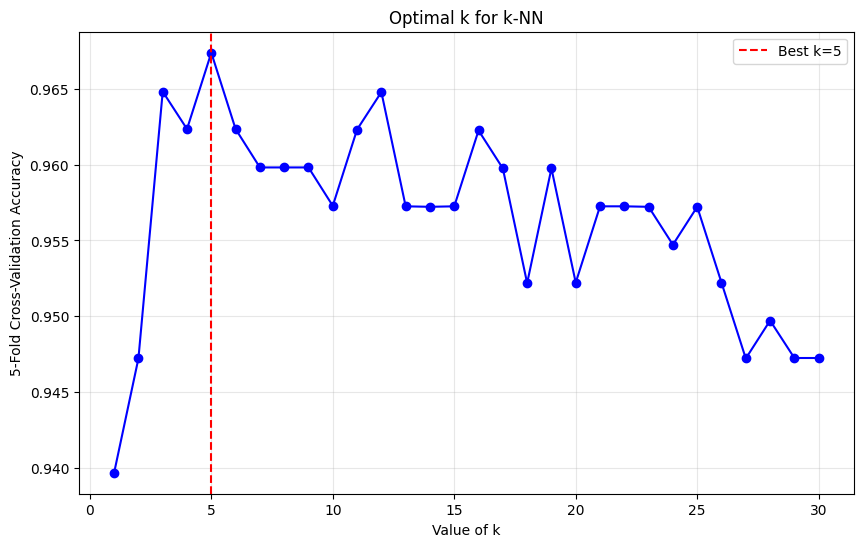

In [13]:
k_range = range(1, 31)
cv_means = []

print("Finding optimal k using 5-Fold Cross-Validation...")
for k in k_range:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(pipe, X_train_log, y_train_log, cv=5, scoring='accuracy')
    cv_means.append(scores.mean())

best_k = list(k_range)[np.argmax(cv_means)]
print(f"Optimal k: {best_k} with CV Accuracy: {max(cv_means):.4f}")

plt.figure(figsize=(10, 6))
plt.plot(list(k_range), cv_means, marker='o', linestyle='-', color='b')
plt.axvline(x=best_k, color='r', linestyle='--', label=f'Best k={best_k}')
plt.xlabel('Value of k')
plt.ylabel('5-Fold Cross-Validation Accuracy')
plt.title('Optimal k for k-NN')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('lab8_optimal_k.png', dpi=200, bbox_inches='tight')
plt.show()

# VII. Guide Questions and Answers

### 1. Linear Regression: Which feature has the strongest impact, and is it positive or negative?
**Answer:** Based on the handout's sample coefficient table, **AveBedrms** has the largest absolute coefficient (about **+0.783**), so the relationship is positive when other features stay constant. This is the largest **raw coefficient**, not a reliable overall feature-importance ranking because the variables have different units. Check your own table above before submitting.

### 2. Logistic Regression: What does the AUC score tell you?
**Answer:** The AUC shows how well the model separates the two tumor classes across different thresholds. A score close to **1.0** means the model distinguishes the classes very well; **0.5** is similar to random guessing.

### 3. Decision Trees: Which one suffered from overfitting?
**Answer:** The **unpruned tree** showed more overfitting in the handout's example: its training accuracy was **1.0000**, but testing accuracy was **0.9181**. The pruned tree scored **0.9799** on training and **0.9240** on testing. The smaller gap suggests that pruning helped generalization. Compare these values with your printed outputs.

### 4. k-NN: Why did accuracy drop without StandardScaler?
**Answer:** k-NN measures distances between data points. Without scaling, features with bigger numeric ranges dominate the Euclidean distance, making some smaller-range features less influential. StandardScaler puts features on comparable scales, which improved accuracy in the handout's experiment.

### 5. Algorithm Selection: Which model would you choose for explainable tumor classification?
**Answer:** I would choose a **Decision Tree** because its decisions can be explained as a sequence of feature-based rules. A doctor can follow the splits to understand why a tumor was classified in a certain way. For actual medical use, the model would still need careful clinical validation.

# Reflection

## Challenges Encountered
I found it challenging to compare the different algorithms and understand why scaling changes k-NN accuracy. Reading the ROC curve and identifying overfitting also took some practice.

## What I Learned
I learned how Linear Regression predicts values, Logistic Regression predicts classes, and Decision Trees make decisions using rules. I also learned that k-NN depends on distance and works better when features are scaled properly.

# Conclusion
This activity helped me understand four supervised learning algorithms. I trained and evaluated Linear Regression, Logistic Regression, Decision Trees, and k-NN using scikit-learn. I learned how model evaluation, pruning, and feature scaling affect results. Overall, the lab improved my understanding of supervised machine learning.

# Submission Checklist
- [ ] Run **Runtime → Restart session and run all** without errors.
- [ ] Screenshot or export the regression metrics and coefficient table.
- [ ] Include the logistic regression classification report, confusion matrix, and ROC curve.
- [ ] Include unpruned and pruned tree diagrams and accuracy comparison.
- [ ] Include scaled vs. unscaled k-NN accuracy and optimal k graph.
- [ ] Check the five guide-question answers against **your own results**.
- [ ] Save the `.ipynb` to your GitHub repository.
- [ ] Export/prepare a final PDF report with student info, source details, results, guide answers, reflection, and conclusion.
- [ ] Submit the GitHub URL and PDF to LMS.